### 逻辑回归
有监督学习：有特征，有标签（离散的）
正例：Positive 反例：Negative
不只是回归问题，逻辑回归更多地适用于二分类问题，逻辑回归直接输出的是一个连续值，将其按值的大小进行切分，不足一定范围的作为一个类别，超过一定范围的作为一个类别，这样就实现了对分类问题的解决。

**核心原理**
- 数据->线性回归->预测值->Sigmoid激活函数->概率[0,1] 然后基于写好的阈值->决定是A还是B
- 即先对数据以线性回归进行拟合，输出值以Sigmoid函数进行映射，映射到0和1之间，最后将S曲线切分上下两个区间作为类别区分的依据。

<img src="./data/logic.png" width="600" align="right" />

### Sigmoid函数 S型函数
**原理**
把 线性回归处理后的值->Sigmoid激活函数 映射到[0,1]之间，结合阈值划分正负样本
线性回归的输出作为逻辑回归的输入

**公式：**
$$
σ(z) = \frac{1}{1+e^{-z}}
$$
- 其中z通常是线性回归的输出即 $z = w^tx + b$，，取值范围为(−∞,+∞)

**作用**
- 数值压缩：将任意实数z映射到(0,1) 区间，使输出可以解释为概率值$p=σ(z)$
- 阈值分类:在逻辑回归中，通常以 0.5 为决策阈值，p≥0.5 预测为正类，否则为负类


### 相关概率知识

**极大似然估**
根据观测到的结果来估计模型算法中的未知参数
给定数据，寻找参数θ，使得数据出现的概率最大

逻辑回归 损失函数 = -极大似然估计函数

**二元交叉熵损失函数（Binary Cross-Entropy Loss）**
$$
Loss(L) = - \frac{1}{m}\left[ \sum_{i=1}^{m} (y_i \log(\hat{p}_i)) + (1 - y_i) \log(1 - \hat{p}_i) \right]
$$
除以样本总量m，以便衡量单样本的“平均损失”，防止损失随着样本值的增加而线性增加

其中逻辑回归的输出概率为：
$$
\hat{p}_i = \text{sigmoid}(w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}
$$

**混淆矩阵**

| 真实 \ 预测 | 预测为：正类（Positive，如恶性） | 预测为：负类（Negative，如良性） |
| :---: | :---: | :---: |
| **真实为：正类（恶性）** | **真正例（TP）** <br> 正确识别出癌症患者 | **假负例（FN）** <br> 漏诊！癌症被误判为健康（Ⅱ型错误） |
| **真实为：负类（良性）** | **假正例（FP）** <br> 误诊！健康人被误判为癌症（Ⅰ型错误） | **真负例（TN）** <br> 正确识别出健康人群 |

### 评估方式
- **精准率** $Precision = \frac{TP}{TP+FP}$

- **召回率** $Recall = \frac{TP}{TP+FN}$

- **精准率** $F1 = 2 * \frac{Precision * Recall}{Precision + Recall}$


在逻辑回归中，我们输出的是概率（0~1），默认以 0.5 作为阈值划分 0 和 1。

如果调高阈值（比如必须大于 0.9 才算癌症）：模型变得保守。癌症病人很难被判出来。
结果：精准率 ↑（不冤枉好人），但召回率 ↓（放走了坏人）。

如果调低阈值（比如只要大于 0.2 就算癌症）：模型变得激进。稍微有点风吹草动就报警。
结果：召回率 ↑（抓出了所有坏人），但精准率 ↓（吓坏了大量好人）。

F1值是 精准率和召回率的调和平均分（其对偏科极其严厉）

**应用场景**
- 逻辑回归（二分类）
- 神经网络输出层（多标签分类或二分类）
- 作为激活函数（早期神经网络）

截距 (Intercept): -32.5841
系数 (Coef): Glucose=1.4580, BMI=0.9304

混淆矩阵：
[[33  2]
 [ 1 24]]

分类报告：
              precision    recall  f1-score   support

          健康       0.97      0.94      0.96        35
         糖尿病       0.92      0.96      0.94        25

    accuracy                           0.95        60
   macro avg       0.95      0.95      0.95        60
weighted avg       0.95      0.95      0.95        60

AUC值: 0.997


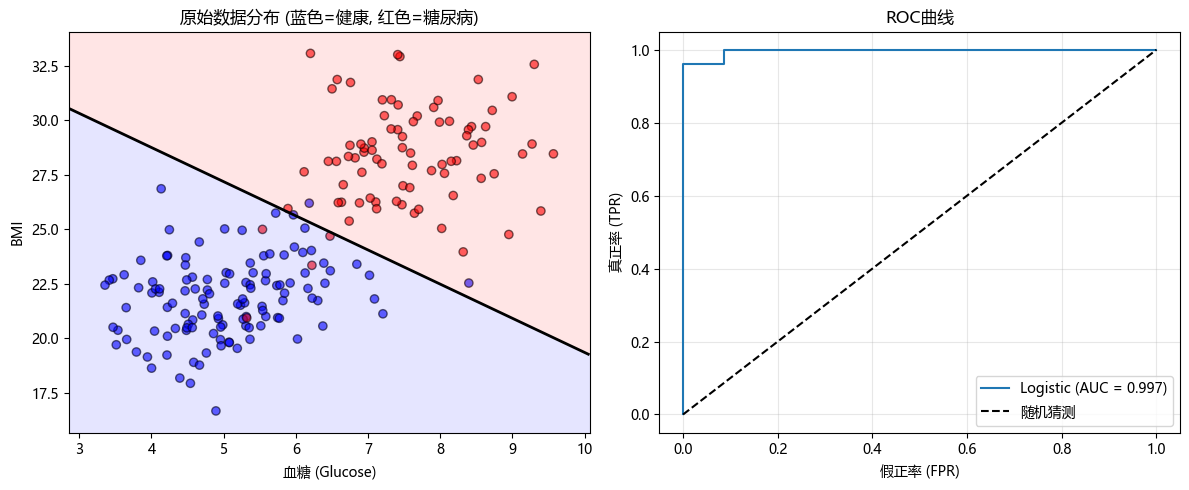

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# 1. 划分训练集和测试集（70% 训练，30% 测试）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. 创建逻辑回归模型（使用默认参数）
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# 3. 输出模型参数（权重和截距）
print(f"截距 (Intercept): {model.intercept_[0]:.4f}")
print(f"系数 (Coef): Glucose={model.coef_[0][0]:.4f}, BMI={model.coef_[0][1]:.4f}")

# 4. 在测试集上进行预测（默认阈值0.5）
y_pred = model.predict(X_test)          # 类别标签（0/1）
y_pred_prob = model.predict_proba(X_test)[:, 1]  # 属于正类（糖尿病）的概率

# 5. 混淆矩阵和评估指标
cm = confusion_matrix(y_test, y_pred)
print("\n混淆矩阵：")
print(cm)

print("\n分类报告：")
print(classification_report(y_test, y_pred, target_names=['健康', '糖尿病']))

# 6. 计算ROC和AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC值: {auc:.3f}")

# 7. 可视化决策边界
plt.figure(figsize=(12, 5))

# 子图1：数据散点 + 决策边界
plt.subplot(1, 2, 1)
# 绘制所有样本，按真实标签着色
colors = ['blue' if l==0 else 'red' for l in y]
plt.scatter(X[:, 0], X[:, 1], c=colors, alpha=0.6, edgecolors='k')
plt.xlabel('血糖 (Glucose)')
plt.ylabel('BMI')
plt.title('原始数据分布 (蓝色=健康, 红色=糖尿病)')

# 绘制逻辑回归的决策边界（概率=0.5的等值线）
x_min, x_max = X[:, 0].min()-0.5, X[:, 0].max()+0.5
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
Z = Z.reshape(xx.shape)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], alpha=0.1, colors=['blue', 'red'])

# 子图2：ROC曲线
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, label=f'Logistic (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测')
plt.xlabel('假正率 (FPR)')
plt.ylabel('真正率 (TPR)')
plt.title('ROC曲线')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('逻辑回归结果.png', dpi=300)
plt.show()

## AUC指标和ROC曲线
**真正率(TPR)**
正样本中被预测为正样本的概率，越大越好
$$
TPR = \frac{TP}{TP + FN}
$$

**假正率(FPR)**
负样本中被预测为正样本的概率，越小越好
$$
FPR = \frac{FP}{TP + FN}
$$

**ROC(Receiver Operating Characteristic)曲线**
以真正率TPR为纵轴，假正率FPR为横轴，以曲线形式展示模型在不同阈值下的表现

**AUC(Area Under the ROC Curve)曲线下面积**
AUC越大表示分类器性能越好，不依赖阈值

